# DSCI 552 - Homework 3

**Name:** Ruturaj Mohalkar  
**GitHub Username:** ruturaj-mohalkar-25  
**USC ID:** 6930537443

## Imports

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 42

# 1. Time Series Classification Part 1: Feature Creation/Extraction

## 1(a) The AReM data set

The AReM (Activity Recognition system based on Multisensor data fusion) data set was downloaded from the UCI Machine Learning Repository and saved under `data/AReM/`. It holds seven folders, one per activity, and each file inside a folder is one instance of a person performing that activity. Every file contains 6 time series (`avg_rss12`, `var_rss12`, `avg_rss13`, `var_rss13`, `avg_rss23`, `var_rss23`), each with 480 consecutive values recorded at 20 Hz over 120 seconds.

**Background.** The data accompanies Palumbo et al. (2016), which studies human activity recognition from a Wireless Sensor Network rather than from wearable accelerometers. Three sensor nodes are worn on the body (chest and both ankles), and what is measured is the **Received Signal Strength (RSS)** between each of the three pairs of nodes: pair 1-2, pair 1-3 and pair 2-3, which is what the suffixes `12`, `13` and `23` mean. RSS varies with the distance and the body tissue between two nodes, so a posture or a movement leaves a characteristic signature in these three signals, and no accelerometer is needed.

The headers inside the files record the sampling scheme: a frequency of 20 Hz, a clock of 250 ms and a duration of 120 seconds. Each row therefore summarizes one 250 ms window of 5 raw readings by its **average (`avg_`) and its variance (`var_`)**, which is why both statistics appear for every pair, and 120 s / 250 ms = 480 rows per instance. The seven activities are bending (in two variants), cycling, lying, sitting, standing and walking.

**Cleaning.** Four files deviate from the common format and the reader below handles all of them:

- `bending2/dataset4.csv` is space-separated rather than comma-separated, and its rows end in a trailing space.
- `cycling/dataset9.csv` and `cycling/dataset14.csv` end their last row with a stray comma, which would otherwise parse as an eighth, empty column.
- `sitting/dataset8.csv` has 479 rows instead of 480, one sample short. It is kept as is, since time-domain features do not require equal lengths.

Splitting each row on any run of commas or whitespace and keeping the first 7 fields covers every case.

In [2]:
DATA_DIR = Path('../data/AReM')
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']


def read_instance(path):
    """Read one AReM file. Handles comma- or space-separated rows and stray trailing separators."""
    rows = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        fields = [f for f in re.split(r'[,\s]+', line) if f]
        rows.append([float(f) for f in fields[:7]])
    return pd.DataFrame(rows, columns=['time'] + SERIES)


activities = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
instances = []
for activity in activities:
    for path in sorted(DATA_DIR.glob(f'{activity}/dataset*.csv'),
                       key=lambda p: int(re.search(r'\d+', p.stem).group())):
        instances.append({
            'activity': activity,
            'dataset': int(re.search(r'\d+', path.stem).group()),
            'data': read_instance(path),
        })

print('Activities:', activities)
print('Instances:', len(instances))
print('Time series per instance:', len(SERIES))
print('Length of each time series:', sorted({len(i['data']) for i in instances}))
pd.Series([i['activity'] for i in instances]).value_counts().rename('instances').to_frame()

Activities: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
Instances: 88
Time series per instance: 6
Length of each time series: [479, 480]


,instances
cycling,15
lying,15
sitting,15
standing,15
walking,15
bending1,7
bending2,6


**Note on lengths:** 87 of the 88 instances have 480 values per series and `sitting/dataset8.csv` has 479, which is the one-sample shortfall described above.

### An example instance

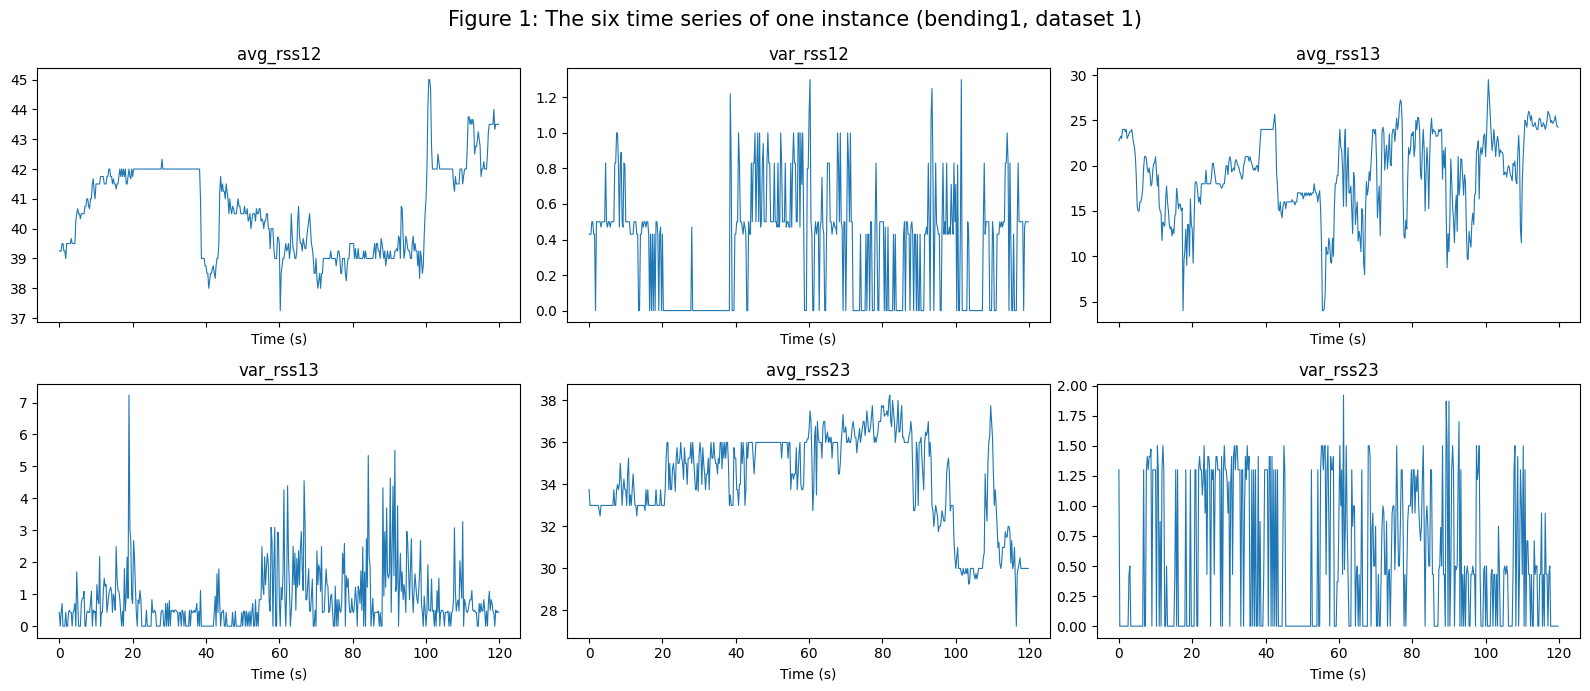

In [3]:
example = instances[0]
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for ax, s in zip(axes.ravel(), SERIES):
    ax.plot(example['data']['time'] / 1000, example['data'][s], lw=0.8)
    ax.set_title(s)
    ax.set_xlabel('Time (s)')
fig.suptitle(f"Figure 1: The six time series of one instance "
             f"({example['activity']}, dataset {example['dataset']})", fontsize=15)
fig.tight_layout()
plt.show()

## 1(b) Train/test split

Datasets 1 and 2 of `bending1` and `bending2`, and datasets 1, 2 and 3 of the other five folders, are kept as test data. Everything else is training data.

In [4]:
def is_test(instance):
    """Datasets 1-2 of the bending folders and 1-3 of the others form the test set."""
    limit = 2 if instance['activity'].startswith('bending') else 3
    return instance['dataset'] <= limit


for instance in instances:
    instance['split'] = 'test' if is_test(instance) else 'train'

split_counts = pd.crosstab([i['activity'] for i in instances], [i['split'] for i in instances])
split_counts.loc['TOTAL'] = split_counts.sum()
split_counts

col_0,test,train
row_0,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12
TOTAL,19,69


## 1(c) Feature Extraction

### 1(c)i. Time-domain features used in time series classification

Time-domain features summarize the raw signal directly, without transforming it to the frequency domain. The ones commonly used in the literature are:

**Location / central tendency**
- Mean, median, mode
- Trimmed mean, and the midrange (min + max) / 2

**Dispersion**
- Standard deviation and variance
- Range (max − min) and interquartile range
- Mean absolute deviation, root mean square (RMS)

**Extremes and order statistics**
- Minimum, maximum
- Quartiles and other percentiles

**Shape of the distribution**
- Skewness (asymmetry) and kurtosis (tailedness)
- Entropy of the value distribution

**Temporal structure**
- Autocorrelation at various lags
- Zero-crossing rate and mean-crossing rate
- Slope or trend from a fitted line, and the mean of the first difference
- Signal magnitude area, energy (sum of squares), peak count, and peak-to-peak amplitude
- Correlation between pairs of axes or channels

This assignment uses seven of them: **minimum, maximum, mean, median, standard deviation, first quartile and third quartile**. These are all order statistics or simple moments, so they are cheap to compute, robust to the exact length of the window, and invariant to the ordering of samples within the window.

### 1(c)ii. Extracting the features

Seven features from each of the 6 time series gives 42 features per instance, for all 88 instances.

In [5]:
FEATURES = {
    'min': np.min,
    'max': np.max,
    'mean': np.mean,
    'median': np.median,
    'std': lambda x: np.std(x, ddof=1),
    '1st_quart': lambda x: np.quantile(x, 0.25),
    '3rd_quart': lambda x: np.quantile(x, 0.75),
}


def extract_features(data):
    """Seven time-domain features for each of the 6 time series of one instance."""
    return {f'{name}{i}': f(data[s].to_numpy())
            for i, s in enumerate(SERIES, start=1)
            for name, f in FEATURES.items()}


features = pd.DataFrame([extract_features(i['data']) for i in instances])
features.insert(0, 'activity', [i['activity'] for i in instances])
features.insert(1, 'dataset', [i['dataset'] for i in instances])
features.insert(2, 'split', [i['split'] for i in instances])
features.index = pd.RangeIndex(1, len(features) + 1, name='Instance')

feature_cols = [c for c in features.columns if c not in ('activity', 'dataset', 'split')]
print('Feature matrix:', features.shape, '->', len(feature_cols), 'features for', len(features), 'instances')
features.head()

Feature matrix: (88, 45) -> 42 features for 88 instances


,activity,dataset,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [6]:
features.round(3)

,activity,dataset,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.625,40.50,1.477,39.25,42.000,...,2.188,33.000,36.00,0.00,1.92,0.571,0.43,0.583,0.000,1.300
2,bending1,2,test,38.00,45.67,42.813,42.50,1.436,42.00,43.670,...,1.995,32.000,34.50,0.00,3.11,0.571,0.43,0.601,0.000,1.300
3,bending1,3,train,35.00,47.40,43.954,44.33,1.559,43.00,45.000,...,2.000,35.362,36.50,0.00,1.79,0.493,0.43,0.514,0.000,0.940
4,bending1,4,train,33.00,47.75,42.180,43.50,3.671,39.15,45.000,...,3.849,30.458,36.33,0.00,2.18,0.614,0.50,0.524,0.000,1.000
5,bending1,5,train,33.00,45.75,41.678,41.75,2.243,41.33,42.750,...,2.411,28.458,31.25,0.00,1.79,0.383,0.43,0.389,0.000,0.500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,walking,11,train,19.50,45.33,33.587,34.25,4.651,30.25,37.000,...,3.284,13.730,18.25,0.00,8.32,3.260,3.11,1.640,2.050,4.322
85,walking,12,train,19.75,45.50,34.323,35.25,4.752,31.00,38.000,...,3.120,13.500,17.75,0.00,9.67,3.433,3.20,1.733,2.157,4.565
86,walking,13,train,19.50,46.00,34.546,35.25,4.842,31.25,37.812,...,2.823,14.000,17.75,0.00,10.00,3.338,3.08,1.657,2.160,4.335


### 1(c)iii. Bootstrap confidence intervals for the standard deviation of each feature

For each of the 42 features, the standard deviation across the 88 instances is estimated, and a 90% confidence interval for it is built by the percentile bootstrap: resample the 88 instances with replacement 10000 times, recompute the standard deviation on each resample, and take the 5th and 95th percentiles of those 10000 values.

In [7]:
N_BOOTSTRAP = 10_000
rng = np.random.default_rng(RANDOM_STATE)


def bootstrap_std_ci(values, n_boot=N_BOOTSTRAP, level=0.90):
    """Percentile bootstrap confidence interval for the standard deviation of `values`."""
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    boot_stds = values[idx].std(axis=1, ddof=1)
    tail = (1 - level) / 2 * 100
    return np.percentile(boot_stds, [tail, 100 - tail])


bootstrap_rows = []
for col in feature_cols:
    values = features[col].to_numpy()
    lower, upper = bootstrap_std_ci(values)
    bootstrap_rows.append({
        'feature': col,
        'std estimate': values.std(ddof=1),
        'CI lower (5%)': lower,
        'CI upper (95%)': upper,
        'CI width': upper - lower,
    })

bootstrap_ci = pd.DataFrame(bootstrap_rows).set_index('feature')
bootstrap_ci.round(4)

,std estimate,CI lower (5%),CI upper (95%),CI width
feature,,,,
min1,9.5700,8.2360,10.7739,2.5379
max1,4.3944,3.3299,5.2966,1.9666
mean1,5.3357,4.6883,5.8891,1.2008
median1,5.4401,4.7958,5.9873,1.1915
std1,1.7722,1.5742,1.9517,0.3775
1st_quart1,6.1536,5.5759,6.6435,1.0676
3rd_quart1,5.1389,4.3263,5.8427,1.5164
min2,0.0000,0.0000,0.0000,0.0000
max2,5.0627,4.6311,5.3999,0.7689


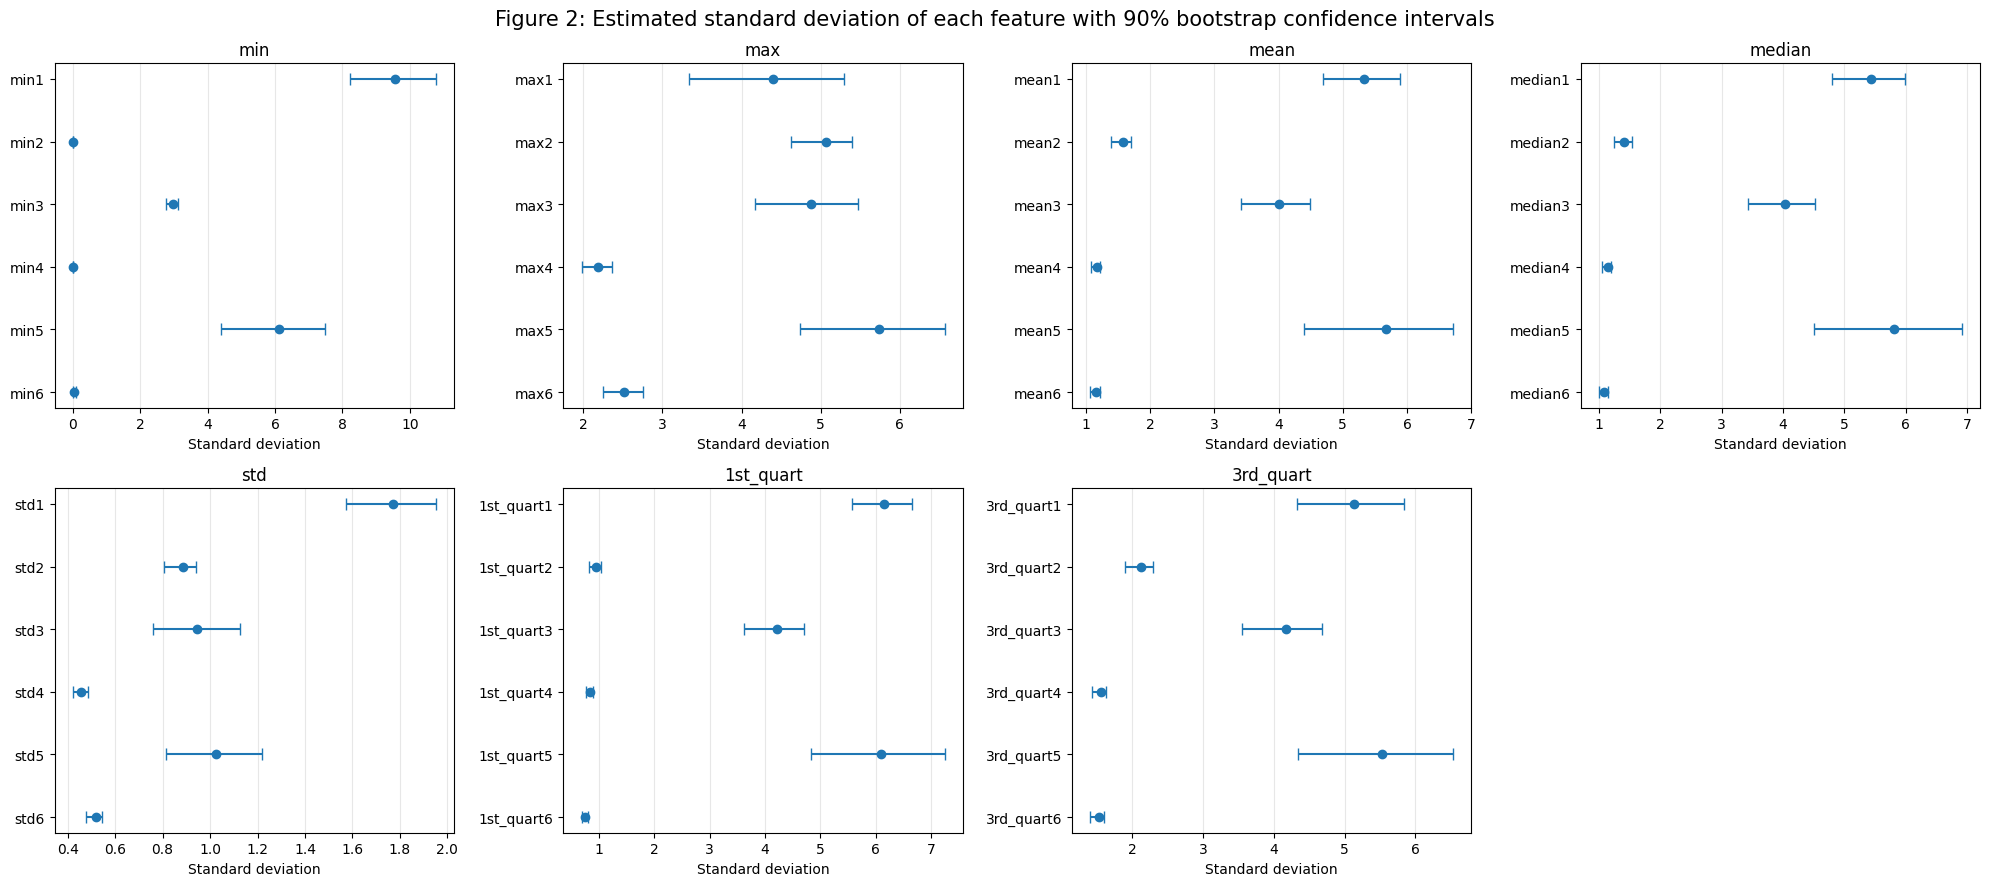

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, (name, _) in zip(axes.ravel(), FEATURES.items()):
    rows = bootstrap_ci.loc[[f'{name}{i}' for i in range(1, 7)]]
    y = np.arange(6)
    ax.errorbar(rows['std estimate'], y,
                xerr=[rows['std estimate'] - rows['CI lower (5%)'],
                      rows['CI upper (95%)'] - rows['std estimate']],
                fmt='o', capsize=4, color='tab:blue')
    ax.set_yticks(y, [f'{name}{i}' for i in range(1, 7)])
    ax.invert_yaxis()
    ax.set_xlabel('Standard deviation')
    ax.set_title(name)
    ax.grid(alpha=0.3, axis='x')
axes.ravel()[-1].axis('off')
fig.suptitle('Figure 2: Estimated standard deviation of each feature with 90% bootstrap confidence intervals',
             fontsize=15)
fig.tight_layout()
plt.show()

### 1(c)iv. The three most important time-domain features

Following the option suggested in the assignment, the three features selected are the **minimum, the mean and the maximum**. Together they describe the range a signal covers and where it sits inside that range: the minimum and maximum bound the signal at both ends, and the mean gives its central level. These are also the cheapest of the seven to compute and the easiest to interpret for activity recognition, where a stationary activity keeps a narrow band between its minimum and maximum and an active one spans a wide band.

In [9]:
SELECTED_FEATURES = ['min', 'mean', 'max']
selected_cols = [f'{name}{i}' for name in SELECTED_FEATURES for i in range(1, 7)]

print('Selected features:', SELECTED_FEATURES)
print('Columns kept:', len(selected_cols))
features[['activity', 'split'] + selected_cols].head()

Selected features: ['min', 'mean', 'max']
Columns kept: 18


,activity,split,min1,min2,min3,min4,min5,min6,mean1,mean2,mean3,mean4,mean5,mean6,max1,max2,max3,max4,max5,max6
Instance,,,,,,,,,,,,,,,,,,,,
1,bending1,test,37.25,0.0,4.0,0.0,27.25,0.0,40.624792,0.358604,19.040937,0.832542,34.311292,0.570583,45.00,1.30,29.50,7.23,38.25,1.92
2,bending1,test,38.00,0.0,2.0,0.0,27.67,0.0,42.812812,0.372437,20.096979,0.876438,33.024583,0.571083,45.67,1.22,29.50,5.76,38.50,3.11
3,bending1,train,35.00,0.0,6.5,0.0,29.00,0.0,43.954500,0.426250,22.122354,0.497312,35.588458,0.493292,47.40,1.70,29.75,4.44,38.50,1.79
4,bending1,train,33.00,0.0,8.5,0.0,20.00,0.0,42.179812,0.696042,22.183625,0.989917,33.493917,0.613521,47.75,3.00,30.00,5.15,38.67,2.18
5,bending1,train,33.00,0.0,3.0,0.0,23.67,0.0,41.678063,0.535979,19.006563,0.841875,29.857083,0.383292,45.75,2.83,28.25,6.42,37.50,1.79


# 2. ISLR 3.7.4

I collect a set of data (n = 100 observations) containing a single predictor and a quantitative response. I then fit a linear regression model to the data, as well as a separate cubic regression, i.e. Y = β₀ + β₁X + β₂X² + β₃X³ + ε.

**(a) Suppose that the true relationship between X and Y is linear. Consider the training residual sum of squares (RSS) for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.**

**The cubic regression will have the lower training RSS**, or at best an equal one. The linear model is a special case of the cubic model with β₂ = β₃ = 0, so least squares on the cubic model searches a strictly larger space of fits and can never do worse on the training data. Even when the true relationship is linear, the extra terms will pick up some of the random noise in the sample, so in practice the cubic training RSS will be strictly smaller. Training RSS never increases when predictors are added.

**(b) Answer (a) using test rather than training RSS.**

**We expect the linear regression to have the lower test RSS.** The true relationship is linear, so the linear model has no bias, and it estimates only two parameters, so its variance is low. The cubic model is also unbiased here, since the true β₂ and β₃ are zero, but it pays for two additional estimated parameters with extra variance, and the curvature it fit to the training noise does not carry over to new data. The expected test error is bias² + variance + irreducible error, so with bias equal the model with the smaller variance wins.

**(c) Suppose that the true relationship between X and Y is not linear, but we don't know how far it is from linear. Consider the training RSS for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.**

**The cubic regression will again have the lower training RSS.** The nesting argument from (a) does not depend on what the true relationship is: the cubic fit minimizes RSS over a superset of the models available to the linear fit, so its training RSS is always less than or equal to the linear model's. Since the true relationship is non-linear here, the gap will typically be larger than in (a), because the extra terms are now capturing real structure as well as noise.

**(d) Answer (c) using test rather than training RSS.**

**There is not enough information to tell.** The answer depends on how far the truth is from linear, which the question says we do not know. If the true relationship is close to linear, say a mild curvature, the bias the linear model suffers is small and it may still win on test RSS thanks to its lower variance. If the true relationship is strongly non-linear, the linear model's bias dominates and the cubic model will have the lower test RSS. Without knowing where between those extremes the truth lies, and how large σ² and n are (these set how much the extra variance costs), neither model can be declared the winner.

## References

1. UCI Machine Learning Repository, AReM Data Set: https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
2. Palumbo, Gallicchio, Pucci, Micheli, *Human activity recognition using multisensor data fusion based on Reservoir Computing*, Journal of Ambient Intelligence and Smart Environments, 2016 (the paper accompanying the data set).
3. Christ, Braun, Neuffer, Kempa-Liehr, *Time Series FeatuRe Extraction on basis of Scalable Hypothesis tests (tsfresh)*, Neurocomputing, 2018. A catalogue of commonly used time-domain features: https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html
4. Efron, Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall, 1993 (percentile bootstrap intervals).
5. NumPy random sampling: https://numpy.org/doc/stable/reference/random/index.html
6. James, Witten, Hastie, Tibshirani, *An Introduction to Statistical Learning*, Springer (Section 3.7, Exercise 4).